# Sniff rasters sorted by position (appetitive epoch)

A different kind of sniff raster: one row per sniff, spikes against latency from inhalation, but rows are grouped by
the nose's bin along the arena's long (y) axis at the inhalation - the same 7 y bins as the "latency profile by y
position" panels in `position_locking.ipynb` / `flip_state_plots.py` - and sorted by sniff duration (shortest first)
within each bin. Only appetitive sniffs are used (inhalation and window end both in the epoch, as in
`position_locking.py`). Each unit gets one raster for all sniffs and one per trial `flip_state` (0/1/2).

- **red bar**: peak of that y bin's latency profile (rate vs latency over the bin's sniffs; 10 ms bins smoothed over
  1 bin, ignoring latencies that fewer than half of the bin's sniffs reach). Bins with < 50 spikes get no bar.
- **blue**: the inhalation (0 ms) and the next inhalation, which shows the duration sort within each bin.
- y tick labels give the y bin and its number of sniffs. Rasters with more than 10,000 sniffs are thinned evenly.

Titles give two scores: **temporal_info z** is how sniff-locked the unit is over the whole session (`info_z` from
`sniff_locking.py`), and **position_timing z** is whether position changes when in the sniff it fires (`timing_z` from
`position_locking.py`, appetitive sniffs).

The plotting code lives in `position_raster.py`.

In [1]:
import sys
sys.path.insert(0, 'sniff-raster-python')  # the analysis modules live there
import pandas as pd
import position_locking as pl
from flip_state_plots import FlipSession, title_stats
from position_raster import plot_position_raster

EPOCH = 'appetitive'
keys = ['mouse', 'session', 'region', 'cluster']
scores = pd.read_csv(f"{pl.OUT_FILE[:-len('.csv')]}_{EPOCH}.csv")
sniff_lock = pd.read_csv('E:/cbm-odor/sniff/sniff_locking.csv')
for d in (scores, sniff_lock):
    d['mouse'] = d['mouse'].astype(str)
scores = scores.merge(sniff_lock[keys + ['info_z', 'info_p', 'peak_latency_ms']], on=keys, how='left', validate='one_to_one')

sessions = {}  # loaded sessions, so units of the same session share one load


def position_raster(mouse, session, cluster, region='ob', save_path=None, show_peaks=False):
    """Position-sorted appetitive sniff rasters of one unit. Returns the peak latency (ms) per y bin of each panel."""
    key = (str(mouse), session, region)
    if key not in sessions:
        sessions[key] = FlipSession(*key[:2], EPOCH, region)
    row = scores[(scores['mouse'] == key[0]) & (scores['session'] == session) & (scores['region'] == region)
                 & (scores['cluster'] == cluster)]
    stats = '' if row.empty else title_stats(row['info_z'].iat[0], row['timing_z'].iat[0])
    peaks = plot_position_raster(sessions[key], int(cluster), stats, save_path, show_peaks=show_peaks)
    return pd.DataFrame(peaks).rename_axis('y bin').T

## Units whose sniff-locking depends most on position

Sniff-locked OB units (whole-session `info_p < 0.05`) with at least 2,000 spikes in the appetitive sniff windows,
ranked by appetitive `interaction_z` - the same ranking as the flip-state section of `position_locking.ipynb`.

,mouse,session,region,cluster,n_sniffs,n_spikes_used,info_z,peak_latency_ms,interaction_z,timing_z
811,9005,x3,ob,11,14672,36703,61.564741,96.0,20.774651,6.297887
834,9005,x4,ob,23,14430,54009,416.884441,152.0,17.040120,3.576810
821,9005,x3,ob,26,14672,49107,33.265804,108.0,16.883002,7.189729
812,9005,x3,ob,14,14672,45975,47.682176,116.0,16.760295,5.360482
820,9005,x3,ob,25,14672,50968,61.709546,102.0,15.251374,7.461652


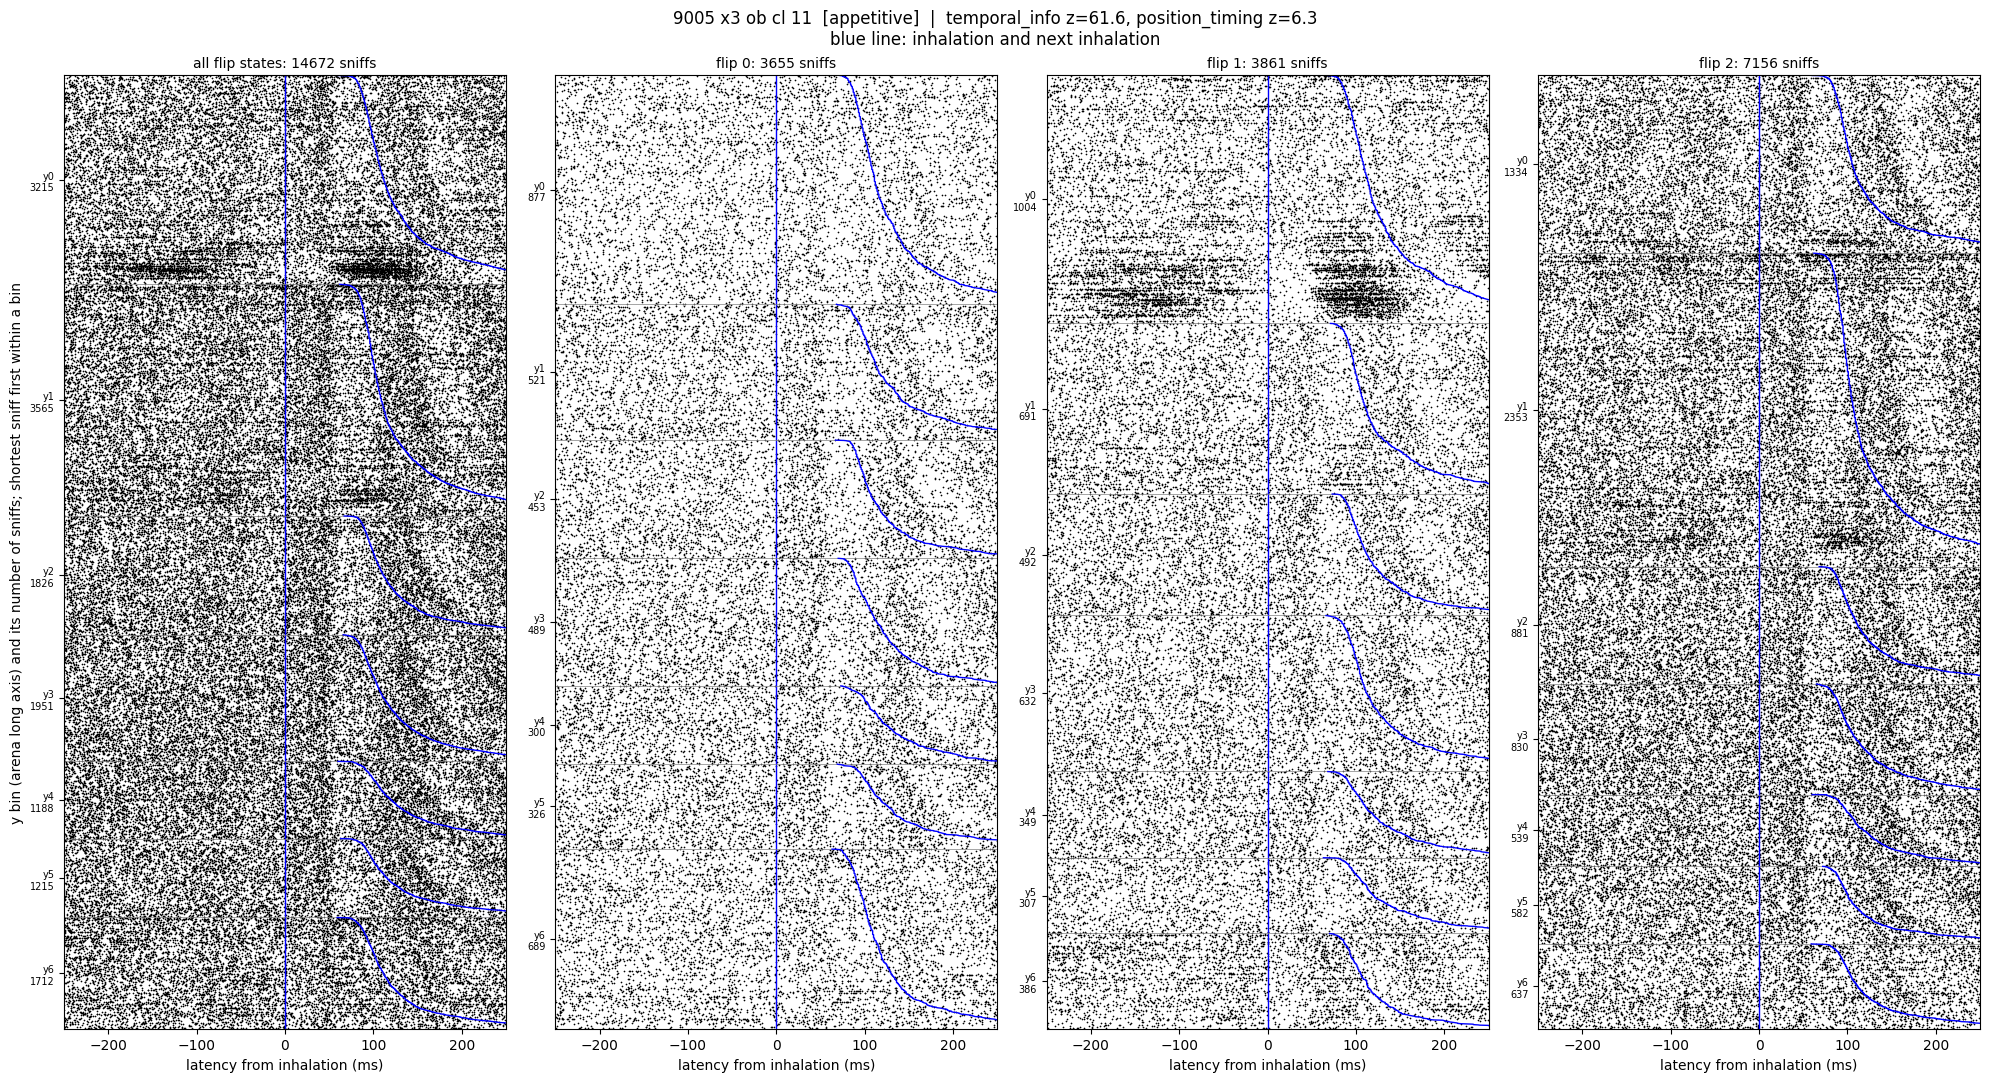

y bin,0,1,2,3,4,5,6
all flip states,105.0,35.0,35.0,35.0,35.0,35.0,45.0
flip 0,45.0,35.0,35.0,35.0,115.0,35.0,45.0
flip 1,115.0,105.0,35.0,35.0,35.0,35.0,65.0
flip 2,35.0,35.0,35.0,35.0,35.0,35.0,45.0


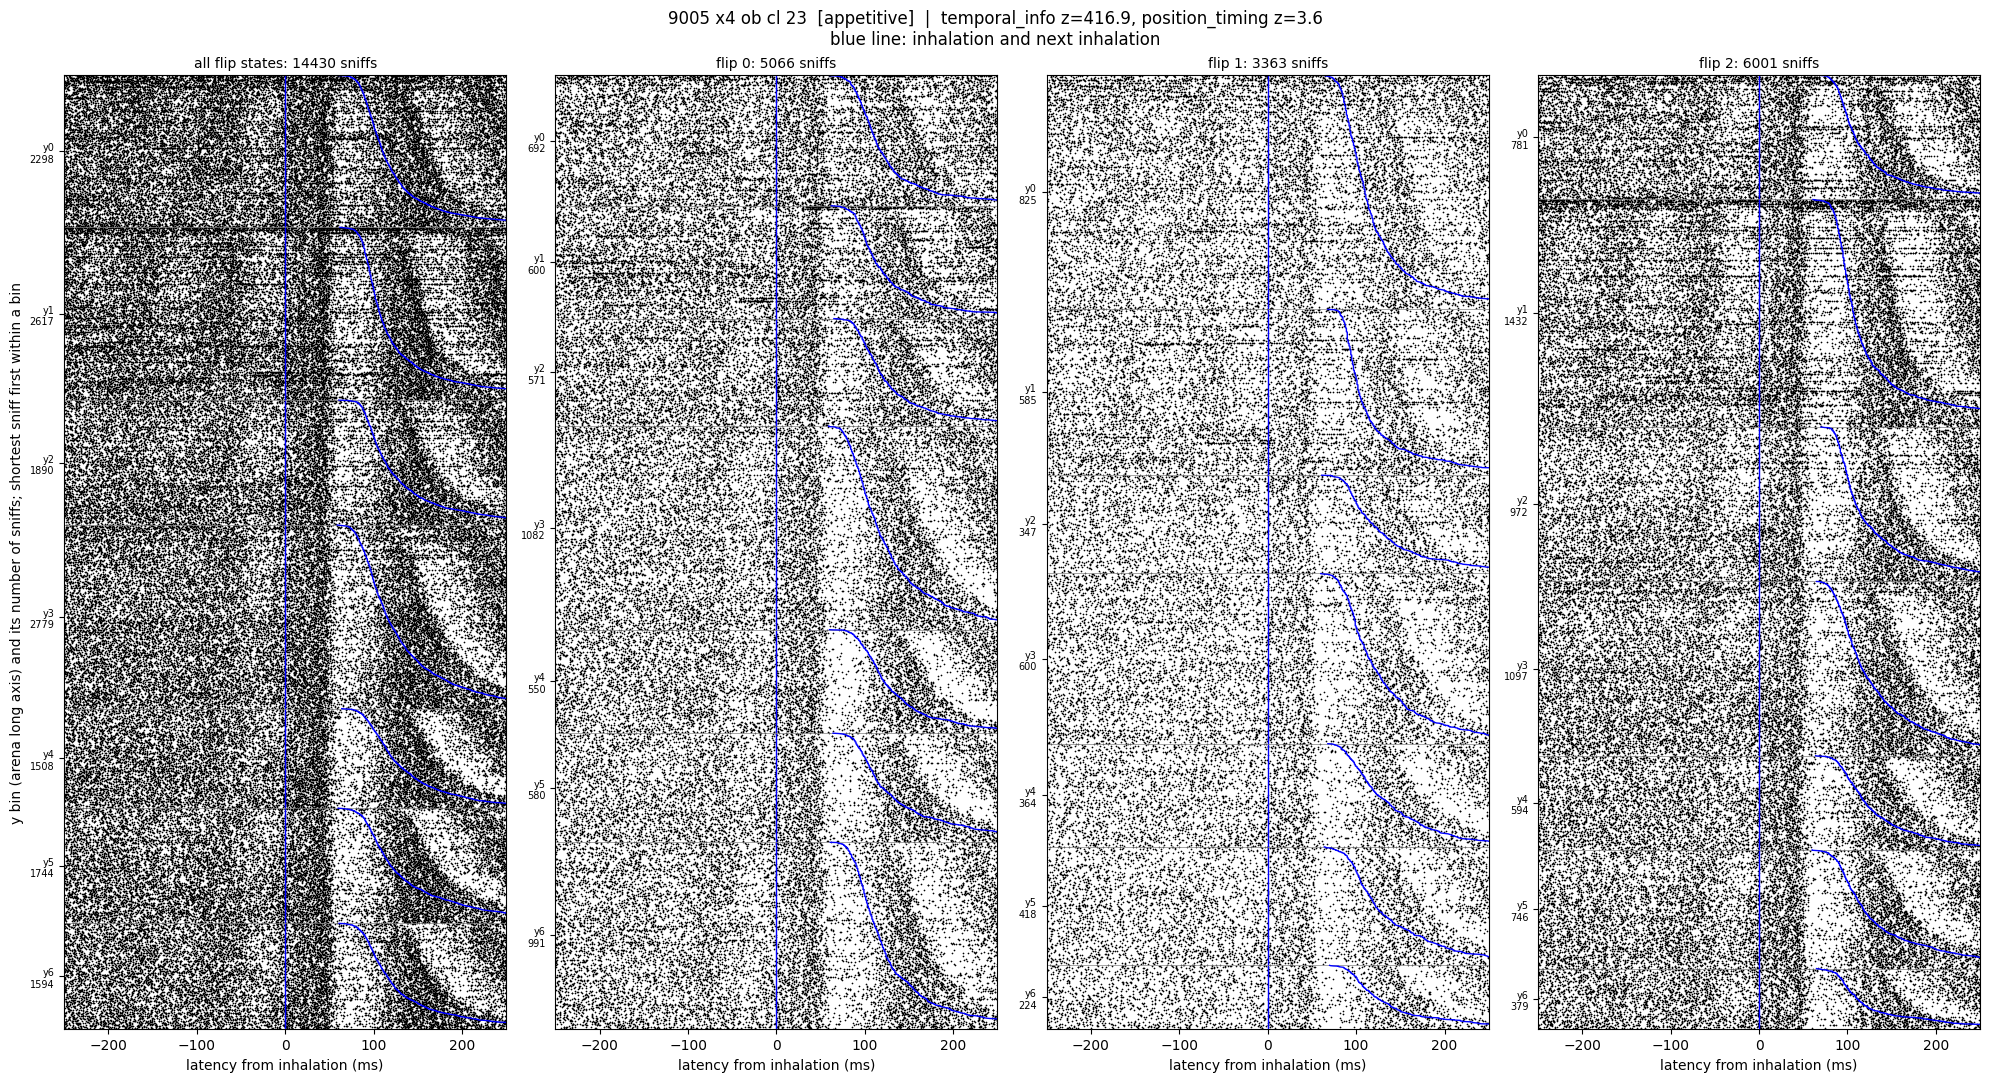

y bin,0,1,2,3,4,5,6
all flip states,35.0,35.0,35.0,35.0,35.0,35.0,35.0
flip 0,35.0,35.0,35.0,35.0,35.0,35.0,35.0
flip 1,35.0,35.0,35.0,35.0,35.0,35.0,35.0
flip 2,35.0,35.0,35.0,35.0,35.0,35.0,35.0


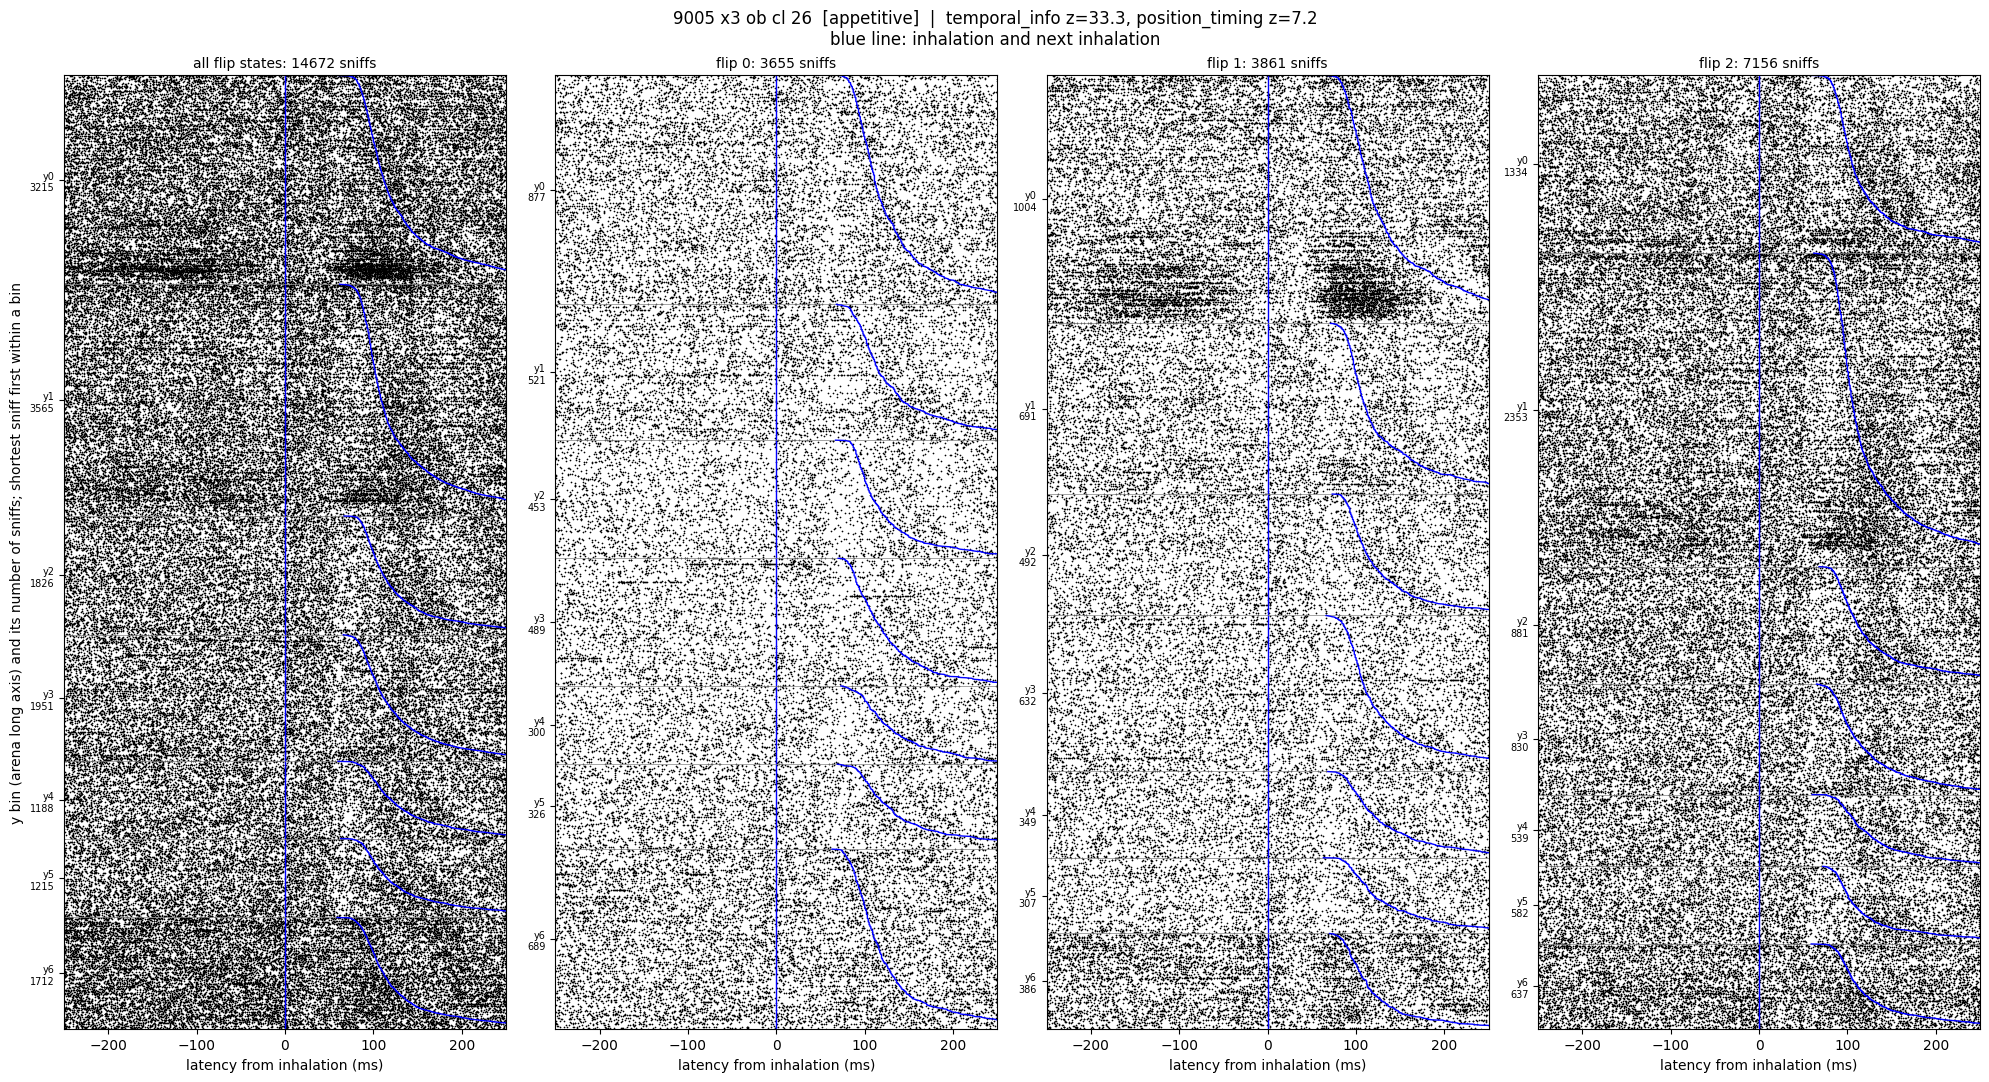

y bin,0,1,2,3,4,5,6
all flip states,105.0,105.0,5.0,5.0,115.0,5.0,105.0
flip 0,5.0,15.0,5.0,5.0,5.0,5.0,105.0
flip 1,115.0,15.0,15.0,105.0,15.0,5.0,85.0
flip 2,105.0,105.0,5.0,105.0,115.0,5.0,105.0


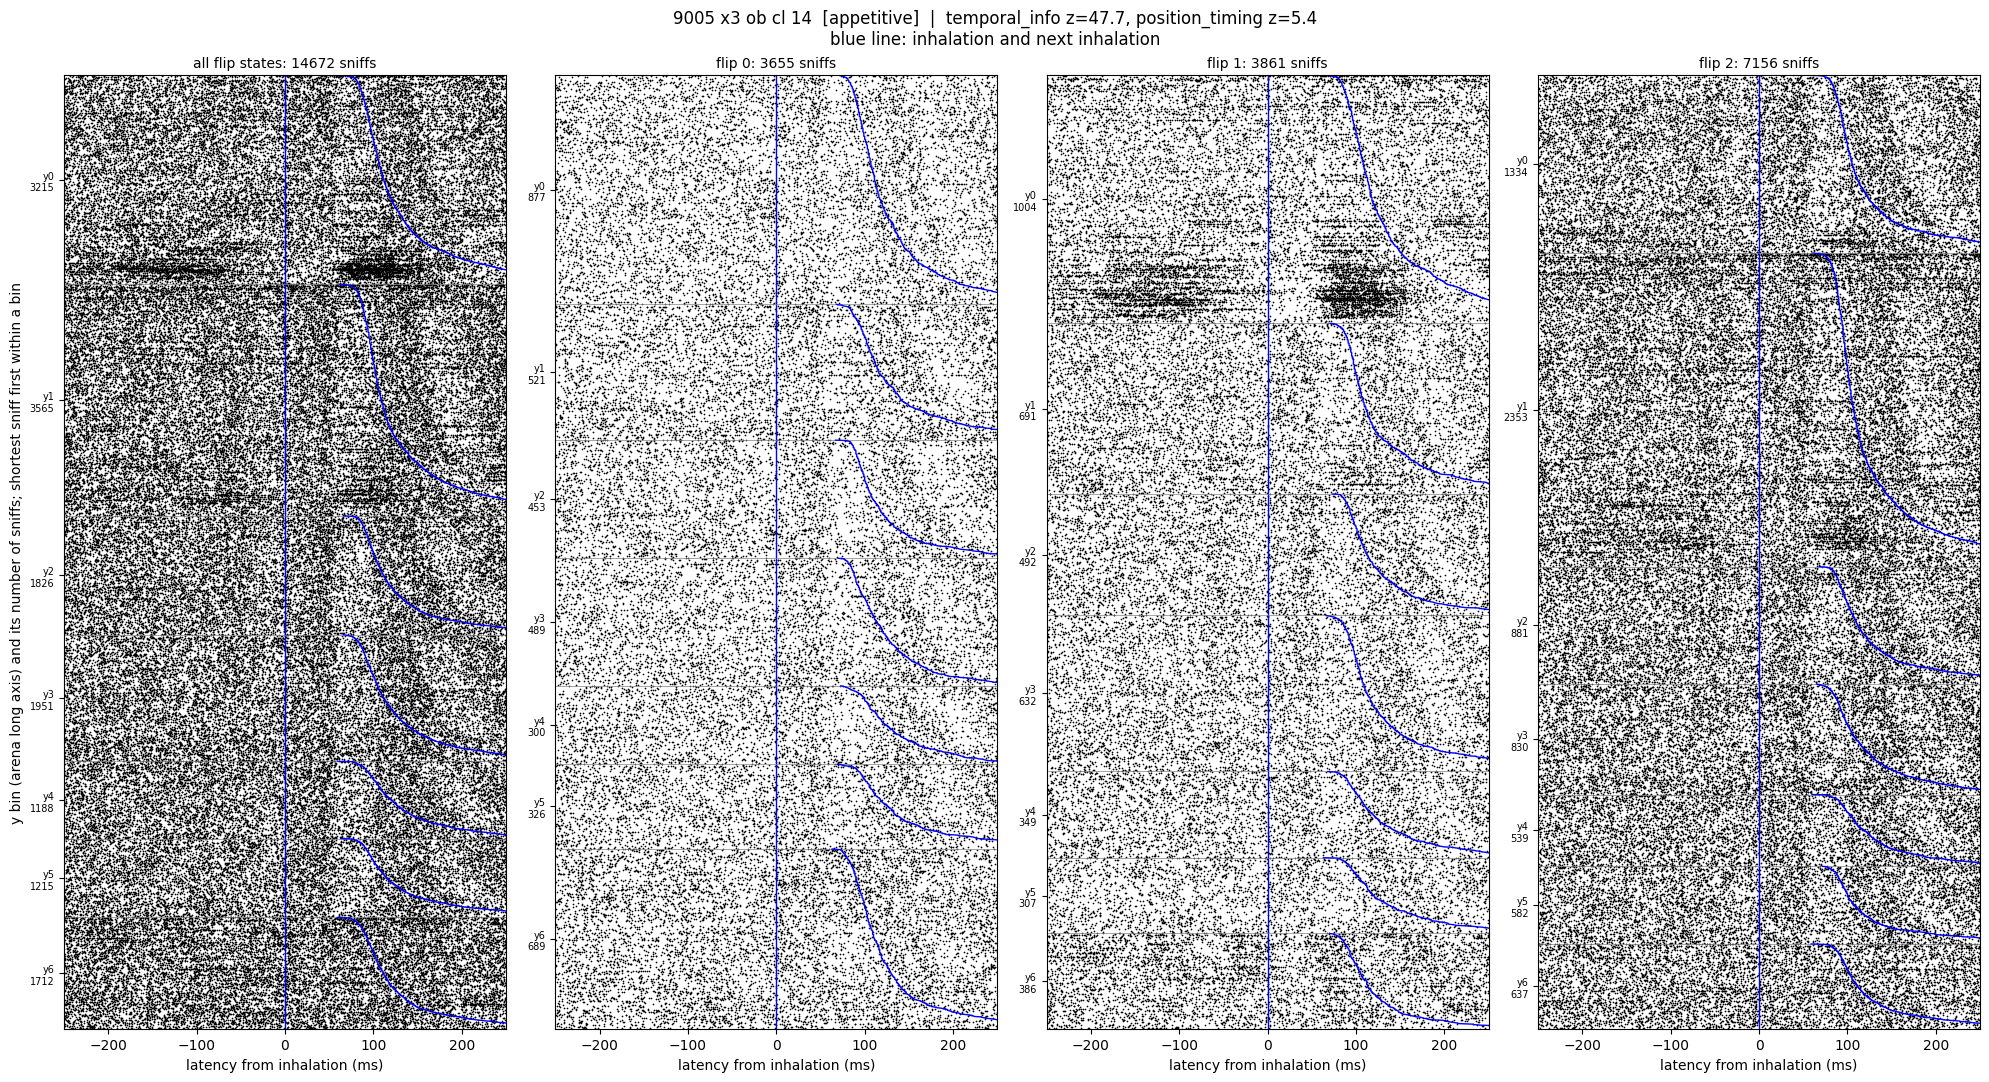

y bin,0,1,2,3,4,5,6
all flip states,105.0,105.0,35.0,35.0,35.0,35.0,5.0
flip 0,45.0,35.0,35.0,35.0,35.0,35.0,5.0
flip 1,115.0,105.0,45.0,35.0,115.0,35.0,75.0
flip 2,105.0,105.0,35.0,45.0,15.0,35.0,105.0


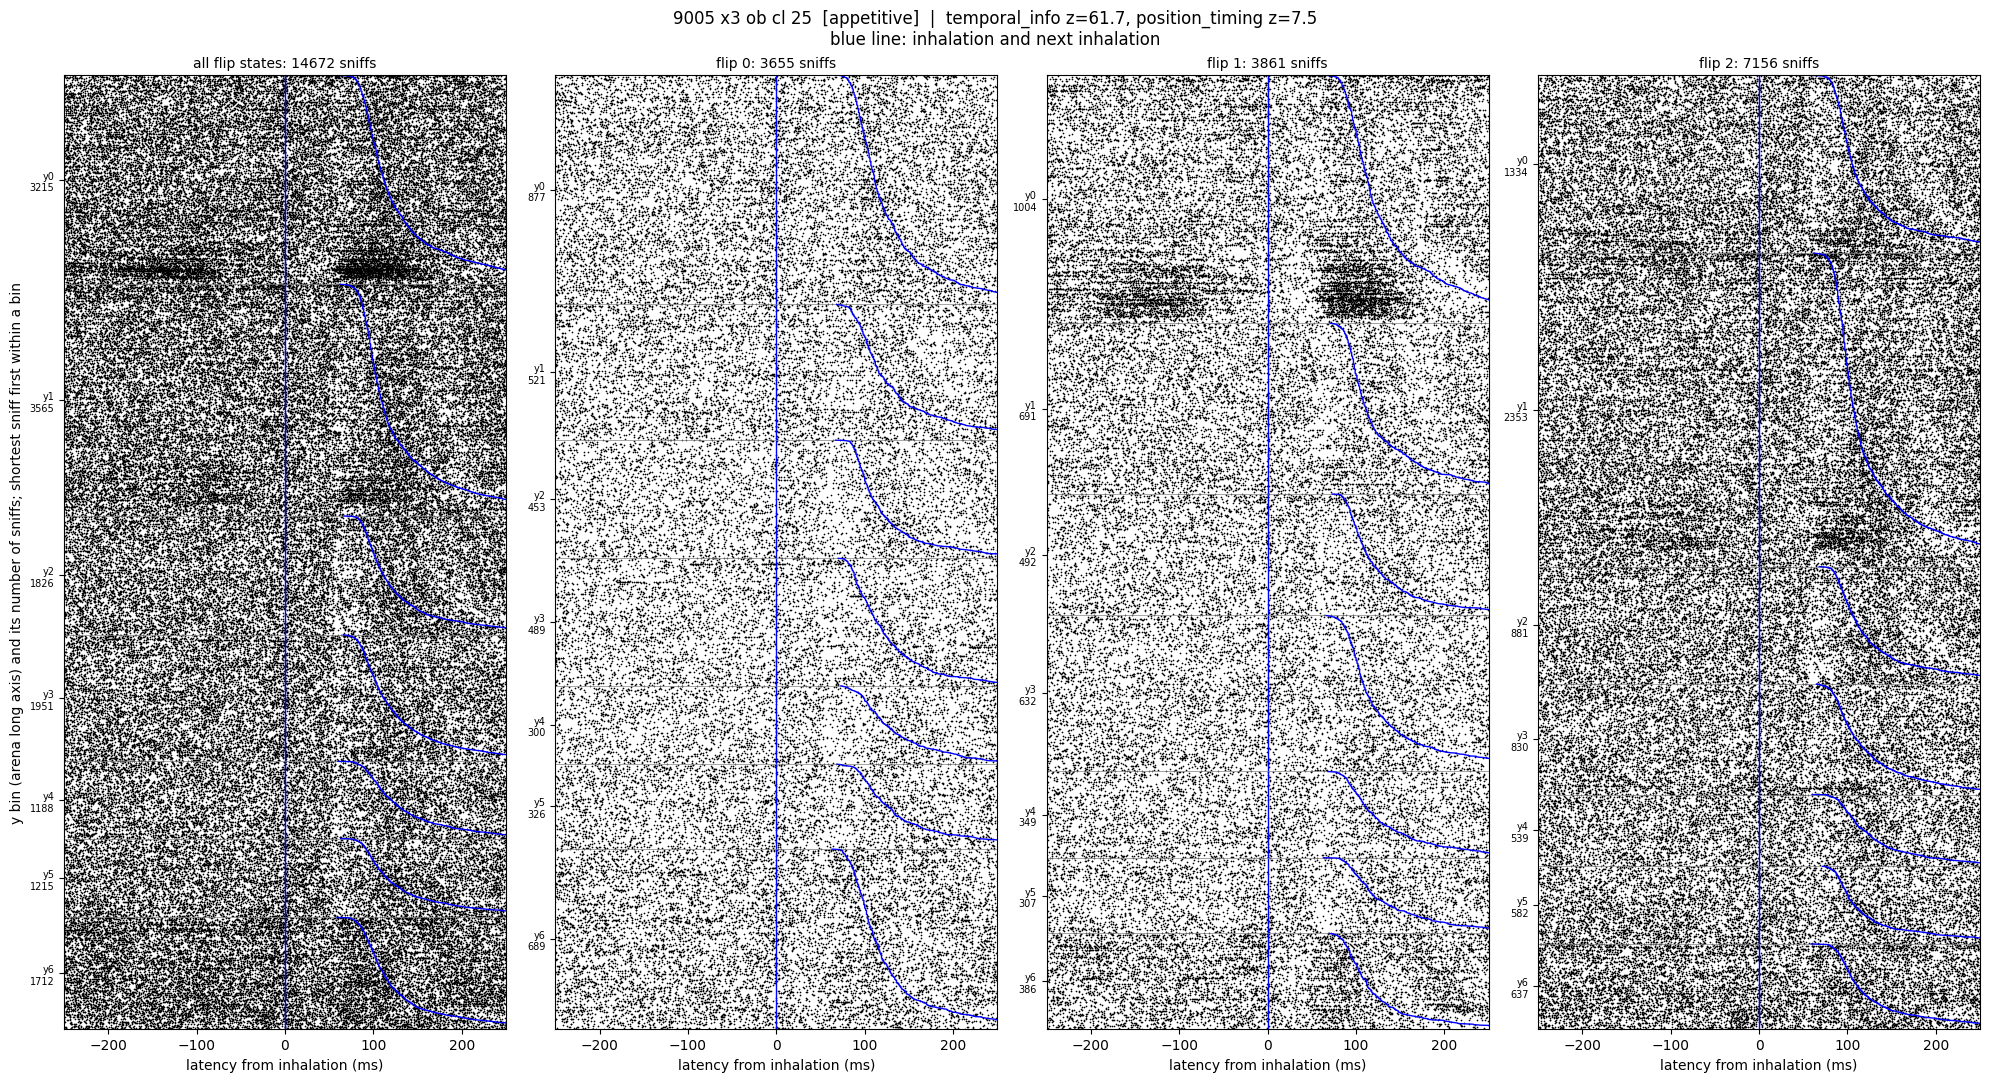

y bin,0,1,2,3,4,5,6
all flip states,105.0,105.0,5.0,105.0,115.0,115.0,85.0
flip 0,105.0,5.0,5.0,5.0,35.0,5.0,85.0
flip 1,115.0,5.0,35.0,105.0,115.0,25.0,85.0
flip 2,105.0,105.0,105.0,105.0,115.0,5.0,105.0


In [2]:
N_UNITS = 5
MIN_SPIKES_RANK = 2000

top = scores[(scores['info_p'] < 0.05) & (scores['n_spikes_used'] >= MIN_SPIKES_RANK)].sort_values('interaction_z', ascending=False)
display(top[keys + ['n_sniffs', 'n_spikes_used', 'info_z', 'peak_latency_ms', 'interaction_z', 'timing_z']].head(N_UNITS))
for _, u in top.head(N_UNITS).iterrows():
    display(position_raster(u['mouse'], u['session'], u['cluster'], u['region']))

## Any unit

`position_raster(mouse, session, cluster, region='ob', save_path=None)` plots one unit and returns the peak latency
(ms) of each y bin for each panel. Pass `save_path` to also write a PNG.

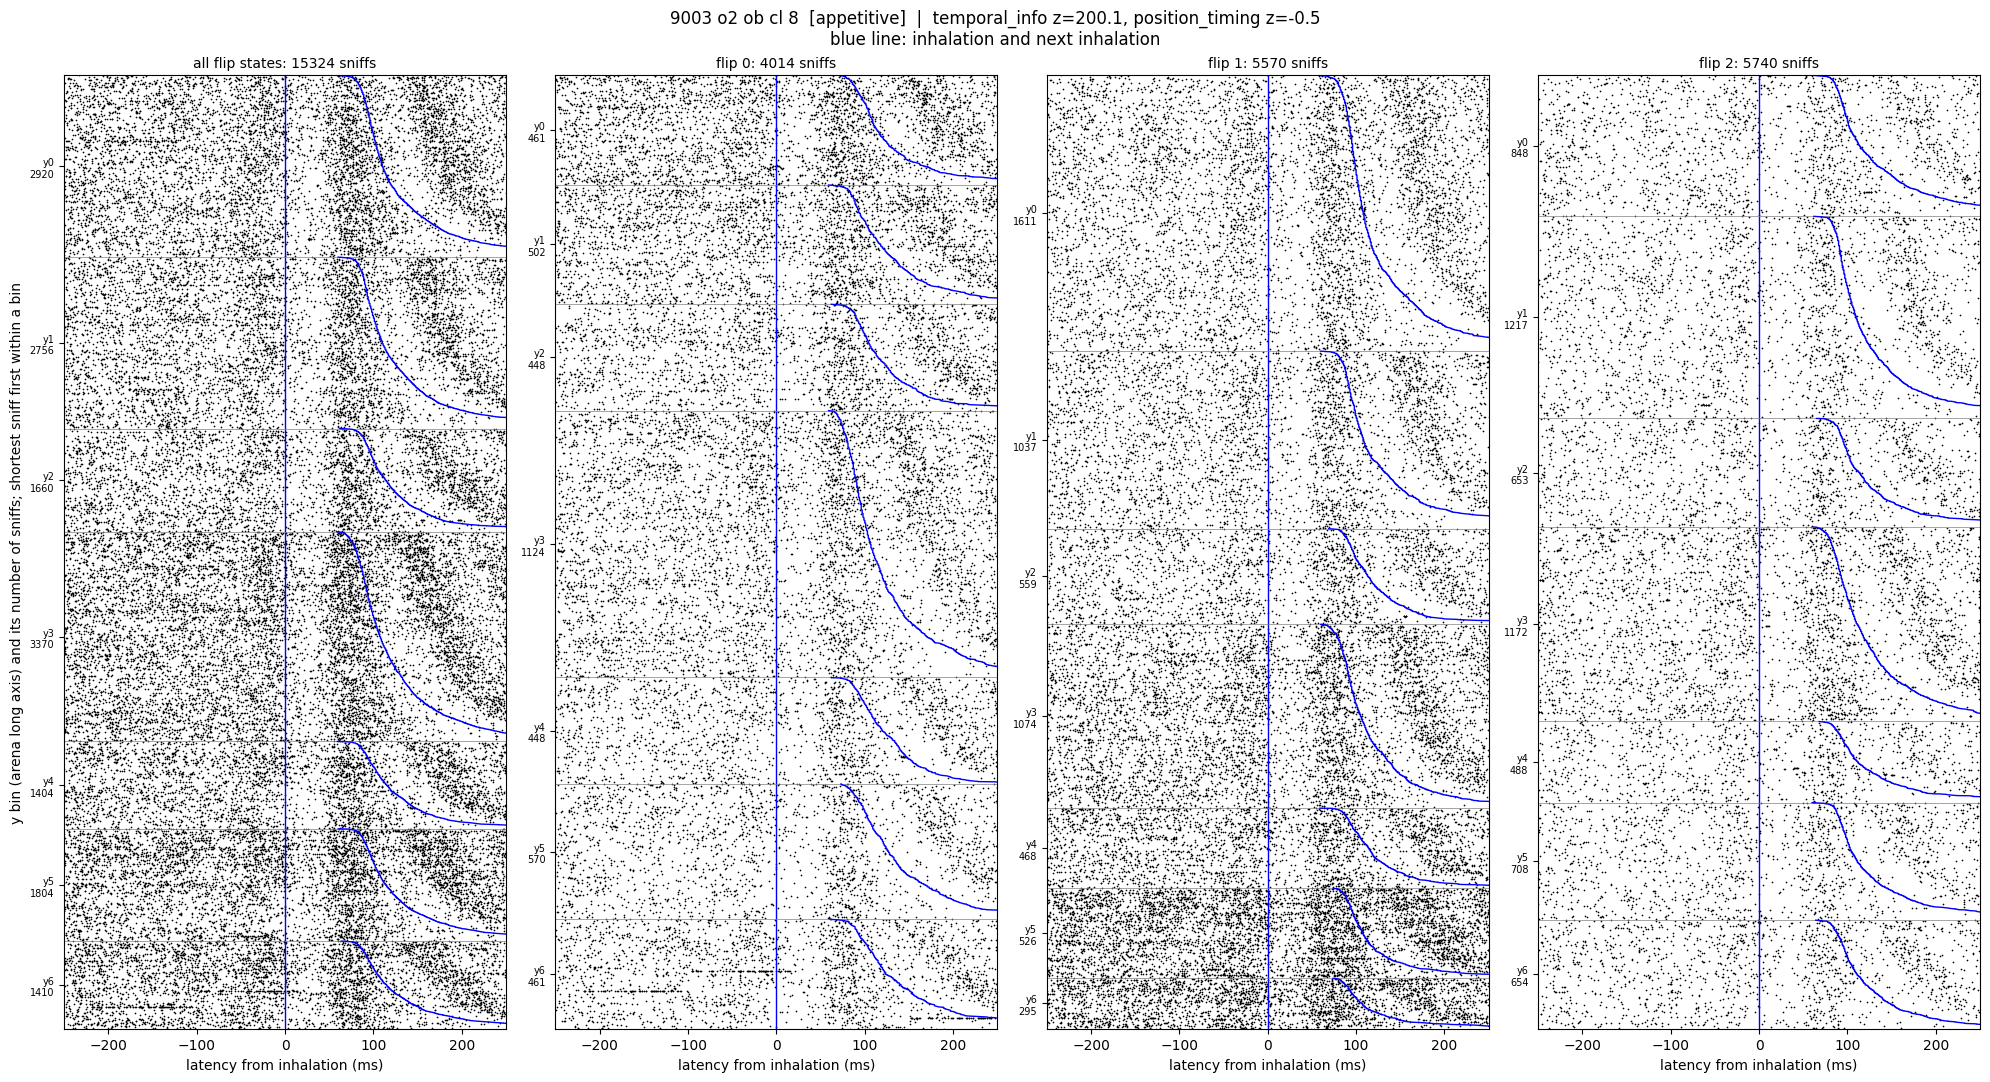

y bin,0,1,2,3,4,5,6
all flip states,75.0,75.0,75.0,75.0,75.0,75.0,75.0
flip 0,75.0,75.0,85.0,75.0,75.0,75.0,75.0
flip 1,75.0,75.0,75.0,75.0,75.0,75.0,75.0
flip 2,85.0,75.0,65.0,75.0,85.0,75.0,75.0


In [3]:
position_raster('9003', 'o2', 8)